# 19. DLinear với neo B trên giao thức chính

Tên đề tài đặt DLinear và NLinear cạnh nhau, nhưng đến hết notebook 18, nhánh DLinear với neo B chỉ có số liệu chấm trên giao thức theo sự kiện đo, tức 36.733 điểm. Con số đó không đặt cạnh được các cấu hình NLinear chấm trên 136.752 điểm của giao thức chính. Sổ tay này lấp chỗ trống đó.

Thiết kế:

- Huấn luyện DLinear neo B với hai hàm mất mát, bình phương và Huber, mỗi hàm năm hạt giống, trên đúng giao thức chính.
- Đối chứng là NLinear neo B cùng hàm mất mát, năm hạt giống, lấy từ các lần đã chạy; thiếu hạt giống nào thì huấn luyện bù.
- Ba phép kiểm định bắt cặp theo hồ sơ: DLinear trừ NLinear với từng hàm mất mát, và Huber trừ bình phương trong DLinear.

DLinear có 1.752 tham số, gấp đôi NLinear với 876 tham số, vì mỗi thành phần xu hướng và phần dư có một lớp tuyến tính riêng. Nếu DLinear không thắng rõ, phần tham số thêm không mua được gì trên dữ liệu thưa và bất quy tắc này.

Cần bộ xử lý đồ họa. Chi phí khoảng mười lăm đến hai mươi phút. Lần nào đã có tệp kết quả thì được đọc lại, nên chạy lại sau khi mất kết nối không phải huấn luyện từ đầu.

> **Vị trí trong chuỗi tái lập:** notebook 19 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh.
>
> **Thư mục kết quả:** `Output/processed/w3_31_dlinear_neo_b_giao_thuc_chinh/`.
>
> **Mã định danh nội bộ:** `W3_31`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_31_dlinear_neo_b_giao_thuc_chinh"  #@param {type:"string"}
HUBER_DELTA = 1.0  #@param {type:"number"}
SO_THAM_SO_DLINEAR = 1752  #@param {type:"integer"}
N_BOOT = 5000  #@param {type:"integer"}
HAT_GIONG_LAY_MAU = 0  #@param {type:"integer"}
MUC_ALPHA = 0.05  #@param {type:"number"}
MSE_MOC_KY_VONG = 0.5787542076552471  #@param {type:"number"}
TONG_DIEM_KY_VONG = 136752  #@param {type:"integer"}
CHAY_LAI_TU_DAU = False  #@param {type:"boolean"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 5      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

# Sổ tay này bắt buộc năm hạt giống, nên giá trị dưới đây ghi đè tham số chung.
N_SEEDS = 5
import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])

Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_31_dlinear_neo_b_giao_thuc_chinh
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:40:20
run_tag      w3_31_dlinear_neo_b_giao_thuc_chinh
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, dữ liệu và hàm dùng chung

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
# Sổ tay tuần 3 cần chính mô hình đã huấn luyện, không chỉ cần chỉ số tổng hợp,
# nên bản này giữ lại mô hình trong bộ nhớ và lưu trọng số ra đĩa.
MO_HINH_DA_HUAN_LUYEN = {}

def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    MO_HINH_DA_HUAN_LUYEN[ten] = model
    if ghi_file and kind != "persistence":
        torch.save(model.state_dict(), thu_muc / (ten + ".pt"))
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


In [8]:
# Đọc tổng sai số theo từng hồ sơ của nhiều tệp rồi lấy trung bình qua các hạt giống.
# Lấy trung bình trước khi bắt cặp, vì biến thiên do hạt giống không phải đối tượng cần đo.
def nap_tong_tu_danh_sach(danh_sach_tep):
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        d = np.load(t)
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


print("Đã định nghĩa hàm đọc tổng sai số theo hồ sơ")


Đã định nghĩa hàm đọc tổng sai số theo hồ sơ


In [9]:
# Hàm dùng chung của ba sổ tay bổ sung: đọc lại lần đã chạy, kiểm số điểm, tìm đối chứng.
def tong_diem_npz(duong):
    """Tổng số điểm chấm trên tập kiểm tra, đọc từ tệp tổng sai số theo hồ sơ."""
    with np.load(duong) as z:
        return int(round(float(np.asarray(z["n"], dtype=np.float64).sum())))


def doc_hoac_chay(ten, thu_muc=None, **tham_so):
    """Đọc lại lần huấn luyện đã có trong thư mục ghi, chưa có thì huấn luyện."""
    thu_muc = RUNS if thu_muc is None else thu_muc
    tep_json = thu_muc / (ten + ".json")
    tep_npz = thu_muc / (ten + "_patient_sums.npz")
    if tep_json.exists() and tep_npz.exists() and not CHAY_LAI_TU_DAU:
        d = json.loads(tep_json.read_text())
        print(ten.ljust(36), "đã có, đọc lại | MSE_obs", round(d["test"]["mse"], 4),
              "| MAE_obs", round(d["test"]["mae"], 4))
        return d
    return chay_mot_cau_hinh(nhan=ten, thu_muc=thu_muc, **tham_so)


def moc_theo_tag():
    """Mốc Persistence của từng lần chạy, dùng để loại lần chạy khác cách chia hoặc khác thang đo."""
    moc = {}
    for tep in sorted((OUT / "processed").glob("*/runs/persistence*.json")):
        try:
            d = json.loads(tep.read_text())
            moc.setdefault(str(d.get("run_tag", tep.parent.parent.name)),
                           float(d["test"]["mse"]))
        except Exception:
            continue
    return moc


def tim_lan_da_co(kind, neo, mat_mat, hat_giong, tong_diem, bo_qua_thu_muc=()):
    """Tìm tệp tổng sai số theo hồ sơ của một cấu hình đã huấn luyện trên giao thức chính.

    Điều kiện ghép giống notebook 22: cùng lần chạy nguồn, cùng độ dài hai cửa sổ,
    cùng mốc Persistence, cùng tổng số điểm chấm. Nếu nhiều bản sao thì giữ bản
    có tên lần chạy sắp sau, đúng quy tắc gộp của notebook 22.
    """
    moc = moc_theo_tag()
    ung_vien = []
    for tep in sorted((OUT / "processed").glob("*/runs/*.json")):
        thu_muc = tep.parent.parent.name
        if thu_muc in bo_qua_thu_muc:
            continue
        if "neolai" in tep.stem or "neotrung" in tep.stem or "sukien" in tep.stem:
            continue
        try:
            d = json.loads(tep.read_text())
        except Exception:
            continue
        if "test" not in d:
            continue
        tag = str(d.get("run_tag", thu_muc))
        if "chia_seed" in tag:
            continue
        if tag in moc and abs(moc[tag] - MSE_MOC_KY_VONG) > 1e-9:
            continue
        if (d.get("kind") != kind or str(d.get("anchor")) != neo
                or str(d.get("loai_mat_mat", "mse")) != mat_mat
                or d.get("seed") != hat_giong):
            continue
        if (d.get("read_tag") != READ_TAG or d.get("seq_len") != SEQ_LEN
                or d.get("pred_len") != PRED_LEN):
            continue
        npz = tep.with_name(tep.stem + "_patient_sums.npz")
        if not npz.exists() or tong_diem_npz(npz) != tong_diem:
            continue
        ung_vien.append((tag, str(npz)))
    if not ung_vien:
        return None, None
    tag, duong = sorted(ung_vien)[-1]
    return Path(duong), tag


def lay_hoac_bu(kind, neo, mat_mat, hat_giong, **them):
    """Lấy lần đã có trên giao thức chính; thiếu thì huấn luyện bù vào thư mục ghi."""
    tep, tag = tim_lan_da_co(kind, neo, mat_mat, hat_giong, TONG_DIEM_KY_VONG,
                             bo_qua_thu_muc=(RUN_TAG,))
    if tep is None:
        ten = kind + "_neo" + neo + "_" + mat_mat + "_s" + str(hat_giong)
        print("Chưa thấy", ten, "trên giao thức chính, huấn luyện bù")
        doc_hoac_chay(ten, kind=kind, anchor=neo, seed=hat_giong,
                      loai_mat_mat=mat_mat, **them)
        tep, tag = RUNS / (ten + "_patient_sums.npz"), RUN_TAG
    assert tong_diem_npz(tep) == TONG_DIEM_KY_VONG, "Sai số điểm ở " + str(tep)
    return tep, tag


def mse_mae_tu_npz(duong):
    with np.load(duong) as z:
        se, ae, n = (np.asarray(z[k], dtype=np.float64) for k in ("se", "ae", "n"))
    return float(se.sum() / (n.sum() + EPS)), float(ae.sum() / (n.sum() + EPS))


def thong_ke(v):
    a = np.asarray(v, dtype=np.float64)
    return float(a.mean()), float(a.std(ddof=1)) if a.size > 1 else 0.0


def phan_loai(ci):
    if float(ci[1]) < 0.0:
        return "bên trái thắng"
    if float(ci[0]) > 0.0:
        return "bên phải thắng"
    return "chưa phân biệt được"


def kiem_dinh_cap(ma, cau_hoi, ten_trai, tep_trai, ten_phai, tep_phai):
    """Kiểm định bắt cặp theo hồ sơ, bên trái trừ bên phải, giá trị âm nghĩa là bên trái tốt hơn."""
    se_t, ae_t, dem_t = nap_tong_tu_danh_sach(tep_trai)
    se_p, ae_p, dem_p = nap_tong_tu_danh_sach(tep_phai)
    assert np.array_equal(dem_t, dem_p), ma + ": hai bên không cùng số điểm theo hồ sơ"
    kd = hieu_so_bat_cap(se_t, ae_t, se_p, ae_p, dem_t, n_boot=N_BOOT,
                         seed=HAT_GIONG_LAY_MAU, alpha=MUC_ALPHA)
    r = {"ma": ma, "cau_hoi": cau_hoi, "ben_trai": ten_trai, "ben_phai": ten_phai,
         "so_hat_giong_trai": len(tep_trai), "so_hat_giong_phai": len(tep_phai),
         "so_ho_so": int(dem_t.size), "so_diem": int(round(float(dem_t.sum())))}
    for k, v in kd.items():
        if not k.startswith("mau_bootstrap"):
            r[k] = v
    r["ket_luan_mse"] = phan_loai(r["hieu_mse_ci"])
    r["ket_luan_mae"] = phan_loai(r["hieu_mae_ci"])
    print(ma, "|", ten_trai, "trừ", ten_phai)
    print("   bình phương", round(r["hieu_mse"], 6), "| khoảng",
          [round(x, 6) for x in r["hieu_mse_ci"]], "|", r["ket_luan_mse"])
    print("   tuyệt đối  ", round(r["hieu_mae"], 6), "| khoảng",
          [round(x, 6) for x in r["hieu_mae_ci"]], "|", r["ket_luan_mae"])
    return r


print("Đã định nghĩa hàm dùng chung của đợt bổ sung")

Đã định nghĩa hàm dùng chung của đợt bổ sung


## 3. Kiểm tra giao thức trước khi huấn luyện

Mọi con số của sổ tay này phải chấm trên đúng giao thức đánh giá chính: lưới cố định 36 giờ vào, 12 giờ ra, 1.585 hồ sơ kiểm tra, 136.752 điểm có phép đo thật. Ô dưới đây kiểm hai điều trước khi tốn thời gian huấn luyện: tổng số điểm chấm của tập kiểm tra, và mốc Persistence tính lại phải trùng mốc của tuần 2 tới chữ số thứ chín. Hai phép kiểm này đảm bảo kết quả mới đặt được cạnh bảng xếp hạng của notebook 22.

In [10]:
TONG_DIEM_TEST = int(round(float(SPLITS["test"].tensors[3].sum())))
print("Tổng số điểm chấm trên tập kiểm tra:", TONG_DIEM_TEST)
assert TONG_DIEM_TEST == TONG_DIEM_KY_VONG, (
    "Tập kiểm tra có " + str(TONG_DIEM_TEST) + " điểm, khác giao thức chính " +
    str(TONG_DIEM_KY_VONG) + " điểm")

p_per = doc_hoac_chay("persistence_luoi", kind="persistence", seed=0)
MSE_MOC = float(p_per["test"]["mse"])
MAE_MOC = float(p_per["test"]["mae"])
LECH_MOC = abs(MSE_MOC - MSE_MOC_KY_VONG)
print("Mốc Persistence:", MSE_MOC, "| lệch so với giá trị kỳ vọng:", LECH_MOC)
assert LECH_MOC < 1e-9, "Mốc Persistence khác giá trị kỳ vọng, kiểm tra lại dữ liệu đọc vào"
assert tong_diem_npz(RUNS / "persistence_luoi_patient_sums.npz") == TONG_DIEM_KY_VONG
print("Giao thức đánh giá khớp giao thức chính")

Tổng số điểm chấm trên tập kiểm tra: 136752
persistence_luoi                 MSE_obs 0.5788 | MAE_obs 0.4659 | 0 giây | 0 tham số
Mốc Persistence: 0.5787542076552471 | lệch so với giá trị kỳ vọng: 0.0
Giao thức đánh giá khớp giao thức chính


## 4. Huấn luyện DLinear neo B với hai hàm mất mát

Mỗi lần huấn luyện dừng sớm theo đúng hàm mất mát đang tối ưu trên tập kiểm định, giống mọi lần chạy trước. Sau mỗi lần, ô kiểm lại số tham số và tổng số điểm chấm.

In [11]:
HAM_MAT_MAT = ("mse", "huber")
SEEDS = list(range(N_SEEDS))
t0 = time.time()
TEP_DLINEAR = {}
for mm in HAM_MAT_MAT:
    TEP_DLINEAR[mm] = []
    for s in SEEDS:
        ten = "dlinear_neoB_" + mm + "_s" + str(s)
        d = doc_hoac_chay(ten, kind="dlinear", anchor="B", seed=s,
                          loai_mat_mat=mm, huber_delta=HUBER_DELTA)
        assert d["n_params"] == SO_THAM_SO_DLINEAR, (
            ten + " có " + str(d["n_params"]) + " tham số, khác " + str(SO_THAM_SO_DLINEAR))
        tep = RUNS / (ten + "_patient_sums.npz")
        assert tong_diem_npz(tep) == TONG_DIEM_KY_VONG, "Sai số điểm ở " + ten
        TEP_DLINEAR[mm].append(tep)
print("Thời gian cả khối:", round(time.time() - t0, 1), "giây")

dlinear_neoB_mse_s0              MSE_obs 0.4354 | MAE_obs 0.4367 | 15 giây | 1752 tham số
dlinear_neoB_mse_s1              MSE_obs 0.4363 | MAE_obs 0.4374 | 9 giây | 1752 tham số
dlinear_neoB_mse_s2              MSE_obs 0.4358 | MAE_obs 0.4366 | 5 giây | 1752 tham số
dlinear_neoB_mse_s3              MSE_obs 0.4358 | MAE_obs 0.4366 | 9 giây | 1752 tham số
dlinear_neoB_mse_s4              MSE_obs 0.4374 | MAE_obs 0.4402 | 7 giây | 1752 tham số
dlinear_neoB_huber_s0            MSE_obs 0.434 | MAE_obs 0.4326 | 9 giây | 1752 tham số
dlinear_neoB_huber_s1            MSE_obs 0.434 | MAE_obs 0.431 | 7 giây | 1752 tham số
dlinear_neoB_huber_s2            MSE_obs 0.4339 | MAE_obs 0.4314 | 7 giây | 1752 tham số
dlinear_neoB_huber_s3            MSE_obs 0.4343 | MAE_obs 0.4307 | 7 giây | 1752 tham số
dlinear_neoB_huber_s4            MSE_obs 0.4343 | MAE_obs 0.4311 | 5 giây | 1752 tham số
Thời gian cả khối: 85.7 giây


## 5. Đối chứng NLinear neo B cùng hàm mất mát

Hàm tìm đối chứng dùng cùng bốn điều kiện ghép với notebook 22. Lần chạy của luật neo lai, luật neo theo tỷ lệ trùng và giao thức theo sự kiện đều bị bỏ qua. Với hàm Huber, ô kiểm thêm tham số ngưỡng của hàm phải trùng nhau.

In [12]:
TEP_NLINEAR, NGUON_NLINEAR = {}, {}
for mm in HAM_MAT_MAT:
    TEP_NLINEAR[mm], NGUON_NLINEAR[mm] = [], []
    for s in SEEDS:
        tep, tag = lay_hoac_bu("nlinear", "B", mm, s, huber_delta=HUBER_DELTA)
        if mm == "huber":
            d = json.loads(tep.with_name(tep.name.replace("_patient_sums.npz", ".json")).read_text())
            assert float(d.get("huber_delta", 1.0)) == HUBER_DELTA, "Khác ngưỡng Huber ở " + str(tep)
        TEP_NLINEAR[mm].append(tep)
        NGUON_NLINEAR[mm].append(tag)
        print("NLinear neo B", mm.ljust(5), "hạt giống", s, "| nguồn", tag)

NLinear neo B mse   hạt giống 0 | nguồn w3_18_chi_so_theo_nhom_kenh
NLinear neo B mse   hạt giống 1 | nguồn w3_18_chi_so_theo_nhom_kenh
NLinear neo B mse   hạt giống 2 | nguồn w3_18_chi_so_theo_nhom_kenh
NLinear neo B mse   hạt giống 3 | nguồn bo_sung_13_neo_abcd_nam_hat_giong
NLinear neo B mse   hạt giống 4 | nguồn bo_sung_13_neo_abcd_nam_hat_giong
NLinear neo B huber hạt giống 0 | nguồn bo_sung_14_huber_neo_b
NLinear neo B huber hạt giống 1 | nguồn bo_sung_14_huber_neo_b
NLinear neo B huber hạt giống 2 | nguồn bo_sung_14_huber_neo_b
NLinear neo B huber hạt giống 3 | nguồn w3_17_luoi_nam_hat_giong
NLinear neo B huber hạt giống 4 | nguồn w3_17_luoi_nam_hat_giong


## 6. Thống kê theo hạt giống

In [13]:
BANG_HAT = []
for ho, tep_theo in (("DLinear", TEP_DLINEAR), ("NLinear", TEP_NLINEAR)):
    for mm in HAM_MAT_MAT:
        for s, tep in zip(SEEDS, tep_theo[mm]):
            m1, m2 = mse_mae_tu_npz(tep)
            BANG_HAT.append({"ho_mo_hinh": ho, "ham_mat_mat": mm, "hat_giong": s,
                             "mse": m1, "mae": m2, "tep": str(tep)})

TOM_TAT = []
for ho in ("DLinear", "NLinear"):
    for mm in HAM_MAT_MAT:
        hang = [r for r in BANG_HAT if r["ho_mo_hinh"] == ho and r["ham_mat_mat"] == mm]
        mse_tb, mse_sd = thong_ke([r["mse"] for r in hang])
        mae_tb, mae_sd = thong_ke([r["mae"] for r in hang])
        TOM_TAT.append({"khoa_cau_hinh": ho.lower() + "|B|" + mm, "so_hat_giong": len(hang),
                        "mse_trung_binh": mse_tb, "mse_do_lech_chuan": mse_sd,
                        "mae_trung_binh": mae_tb, "mae_do_lech_chuan": mae_sd})
        print(ho.ljust(8), "neo B |", mm.ljust(5), "| bình phương", round(mse_tb, 6),
              "cộng trừ", round(mse_sd, 6), "| tuyệt đối", round(mae_tb, 6),
              "cộng trừ", round(mae_sd, 6))

DLinear  neo B | mse   | bình phương 0.436128 cộng trừ 0.000747 | tuyệt đối 0.437512 cộng trừ 0.001527
DLinear  neo B | huber | bình phương 0.434091 cộng trừ 0.000211 | tuyệt đối 0.431355 cộng trừ 0.000713
NLinear  neo B | mse   | bình phương 0.436195 cộng trừ 0.000542 | tuyệt đối 0.437632 cộng trừ 0.000963
NLinear  neo B | huber | bình phương 0.433972 cộng trừ 0.000291 | tuyệt đối 0.43127 cộng trừ 0.000668


## 7. Kiểm định bắt cặp theo hồ sơ

Mỗi bên là trung bình tổng sai số theo hồ sơ qua năm hạt giống. Năm nghìn lần lấy mẫu lặp theo hồ sơ, hạt giống lấy mẫu bằng không, đúng bộ tham số của notebook 23.

In [14]:
CAC_PHEP = [
    ("D01", "DLinear có khác NLinear khi cùng neo B và cùng hàm bình phương không",
     "dlinear|B|mse", TEP_DLINEAR["mse"], "nlinear|B|mse", TEP_NLINEAR["mse"]),
    ("D02", "DLinear có khác NLinear khi cùng neo B và cùng hàm Huber không",
     "dlinear|B|huber", TEP_DLINEAR["huber"], "nlinear|B|huber", TEP_NLINEAR["huber"]),
    ("D03", "Trong DLinear neo B, hàm Huber có hơn hàm bình phương không",
     "dlinear|B|huber", TEP_DLINEAR["huber"], "dlinear|B|mse", TEP_DLINEAR["mse"]),
]
KET_QUA = [kiem_dinh_cap(*p) for p in CAC_PHEP]

D01 | dlinear|B|mse trừ nlinear|B|mse
   bình phương -6.7e-05 | khoảng [-0.000306, 0.000191] | chưa phân biệt được
   tuyệt đối   -0.00012 | khoảng [-0.000241, -1e-06] | bên trái thắng
D02 | dlinear|B|huber trừ nlinear|B|huber
   bình phương 0.000119 | khoảng [-0.000154, 0.000406] | chưa phân biệt được
   tuyệt đối   8.4e-05 | khoảng [-4.7e-05, 0.000214] | chưa phân biệt được
D03 | dlinear|B|huber trừ dlinear|B|mse
   bình phương -0.002038 | khoảng [-0.003403, -0.000616] | bên trái thắng
   tuyệt đối   -0.006157 | khoảng [-0.006701, -0.005614] | bên trái thắng


## 8. Hình so sánh DLinear và NLinear

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_31_dlinear_neo_b_giao_thuc_chinh/figures/W3_31_dlinear_so_voi_nlinear.png


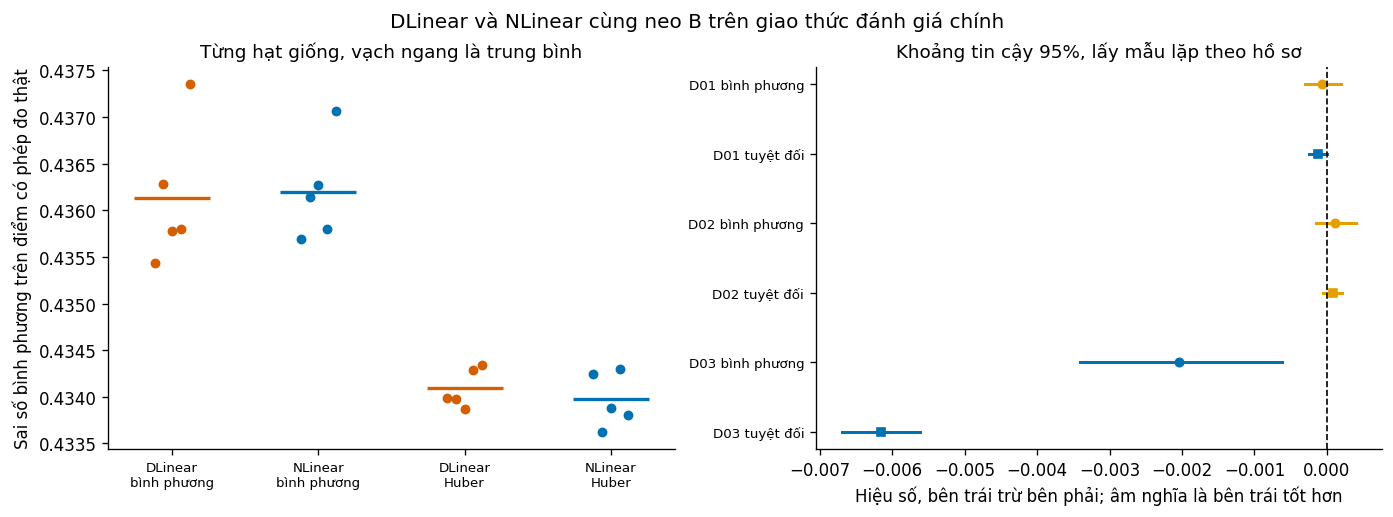

D01 | DLinear có khác NLinear khi cùng neo B và cùng hàm bình phương không
D02 | DLinear có khác NLinear khi cùng neo B và cùng hàm Huber không
D03 | Trong DLinear neo B, hàm Huber có hơn hàm bình phương không


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
NHOM_VE = [
    ("DLinear\nbình phương", [r["mse"] for r in BANG_HAT if r["ho_mo_hinh"] == "DLinear" and r["ham_mat_mat"] == "mse"], PALETTE[1]),
    ("NLinear\nbình phương", [r["mse"] for r in BANG_HAT if r["ho_mo_hinh"] == "NLinear" and r["ham_mat_mat"] == "mse"], PALETTE[0]),
    ("DLinear\nHuber", [r["mse"] for r in BANG_HAT if r["ho_mo_hinh"] == "DLinear" and r["ham_mat_mat"] == "huber"], PALETTE[1]),
    ("NLinear\nHuber", [r["mse"] for r in BANG_HAT if r["ho_mo_hinh"] == "NLinear" and r["ham_mat_mat"] == "huber"], PALETTE[0]),
]
for i, (nhan_nhom, gia_tri, mau) in enumerate(NHOM_VE):
    v = np.asarray(gia_tri, dtype=np.float64)
    ax[0].scatter(np.full(v.size, i) + np.linspace(-0.12, 0.12, v.size), v, s=24, color=mau)
    ax[0].hlines(v.mean(), i - 0.26, i + 0.26, color=mau, lw=2.0)
ax[0].set_xticks(range(len(NHOM_VE)))
ax[0].set_xticklabels([x[0] for x in NHOM_VE], fontsize=8)
ax[0].set_ylabel("Sai số bình phương trên điểm có phép đo thật")
ax[0].set_title("Từng hạt giống, vạch ngang là trung bình")

KQ_VE = KET_QUA
hang = 0
nhan_hang = []
for r in KQ_VE:
    for ct, ky_hieu in (("mse", "o"), ("mae", "s")):
        lo, hi = r["hieu_" + ct + "_ci"]
        mau = PALETTE[0] if hi < 0 else (PALETTE[1] if lo > 0 else PALETTE[4])
        ax[1].plot([lo, hi], [hang, hang], color=mau, lw=1.8)
        ax[1].plot([r["hieu_" + ct]], [hang], ky_hieu, color=mau, ms=5)
        nhan_hang.append(r["ma"] + " " + ("bình phương" if ct == "mse" else "tuyệt đối"))
        hang += 1
ax[1].axvline(0.0, color=PALETTE[6], ls="--", lw=1.0)
ax[1].set_yticks(range(hang))
ax[1].set_yticklabels(nhan_hang, fontsize=8)
ax[1].invert_yaxis()
ax[1].set_xlabel("Hiệu số, bên trái trừ bên phải; âm nghĩa là bên trái tốt hơn")
ax[1].set_title("Khoảng tin cậy 95%, lấy mẫu lặp theo hồ sơ")
fig.suptitle("DLinear và NLinear cùng neo B trên giao thức đánh giá chính")
luu_hinh(fig, "W3_31_dlinear_so_voi_nlinear.png")
plt.show()
for r in KQ_VE:
    print(r["ma"], "|", r["cau_hoi"])

## 9. Ghi tệp tổng hợp

In [16]:
TONG_HOP = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG, "read_tag": READ_TAG,
    "giao_thuc": meta.get("protocol"), "tong_diem": TONG_DIEM_TEST,
    "mse_persistence": MSE_MOC, "mae_persistence": MAE_MOC,
    "n_seeds": N_SEEDS, "n_boot": N_BOOT, "hat_giong_lay_mau": HAT_GIONG_LAY_MAU,
    "muc_alpha": MUC_ALPHA, "don_vi_lay_mau": "ho_so_benh_nhan",
    "huber_delta": HUBER_DELTA,
    "so_tham_so": {"dlinear": SO_THAM_SO_DLINEAR, "nlinear": SO_THAM_SO_DLINEAR // 2},
    "tung_hat_giong": BANG_HAT, "tom_tat": TOM_TAT,
    "nguon_doi_chung": NGUON_NLINEAR, "kiem_dinh": KET_QUA,
    "env": ENV,
}
DICH = RUN_DIR / "W3_dlinear_neo_b_giao_thuc_chinh.json"
DICH.write_text(json.dumps(TONG_HOP, ensure_ascii=False, indent=1), encoding="utf-8")
print("Đã ghi", DICH.name, "|", DICH.stat().st_size, "byte")
print("")
print("Bước kế tiếp: chạy các sổ tay bổ sung còn lại, rồi chạy notebook 22 đến notebook 26 để hợp nhất")

Đã ghi W3_dlinear_neo_b_giao_thuc_chinh.json | 10337 byte

Bước kế tiếp: chạy các sổ tay bổ sung còn lại, rồi chạy notebook 22 đến notebook 26 để hợp nhất
